# DBSCAN: serial, P1 y P2
Corre las tres versiones de C++ sobre `10000_data.csv` (4 hilos en P1 y P2, k=4 en P2), imprime los speedups y grafica los outliers.

In [1]:
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) != "dbscan":
    os.chdir("dbscan")

N = 10000
THREADS = 4
K = 4

data = f"data/{N}_data.csv"
if not os.path.exists(data):
    subprocess.run(["python3", "generate_data.py", str(N)], check=True)

n_rows = sum(1 for _ in open(data))
assert n_rows == N, f"{data} tiene {n_rows} puntos, se esperaban {N}"
print("Datos:", os.path.abspath(data), f"({n_rows} puntos)")

subprocess.run(["make", "-B"], check=True, capture_output=True)

runs = {
    "Serial": ["./dbscan_serial", data, f"data/{N}_results_serial.csv"],
    "P1": ["./dbscan_p1", data, f"data/{N}_results_p1.csv", str(THREADS)],
    "P2": ["./dbscan_p2", data, f"data/{N}_results_p2.csv", str(THREADS), str(K)],
}

times = {}
for name, cmd in runs.items():
    out = subprocess.run(cmd, capture_output=True, text=True, check=True).stdout
    times[name] = float(out.strip())

print(f"n = {N}, threads = {THREADS}, k (P2) = {K}\n")
for name, t in times.items():
    print(f"{name:7s} {t:.6f} s   speedup {times['Serial'] / t:.2f}x")

n = 10000, threads = 4, k (P2) = 4

Serial  0.042204 s   speedup 1.00x
P1      0.015484 s   speedup 2.73x
P2      0.016316 s   speedup 2.59x


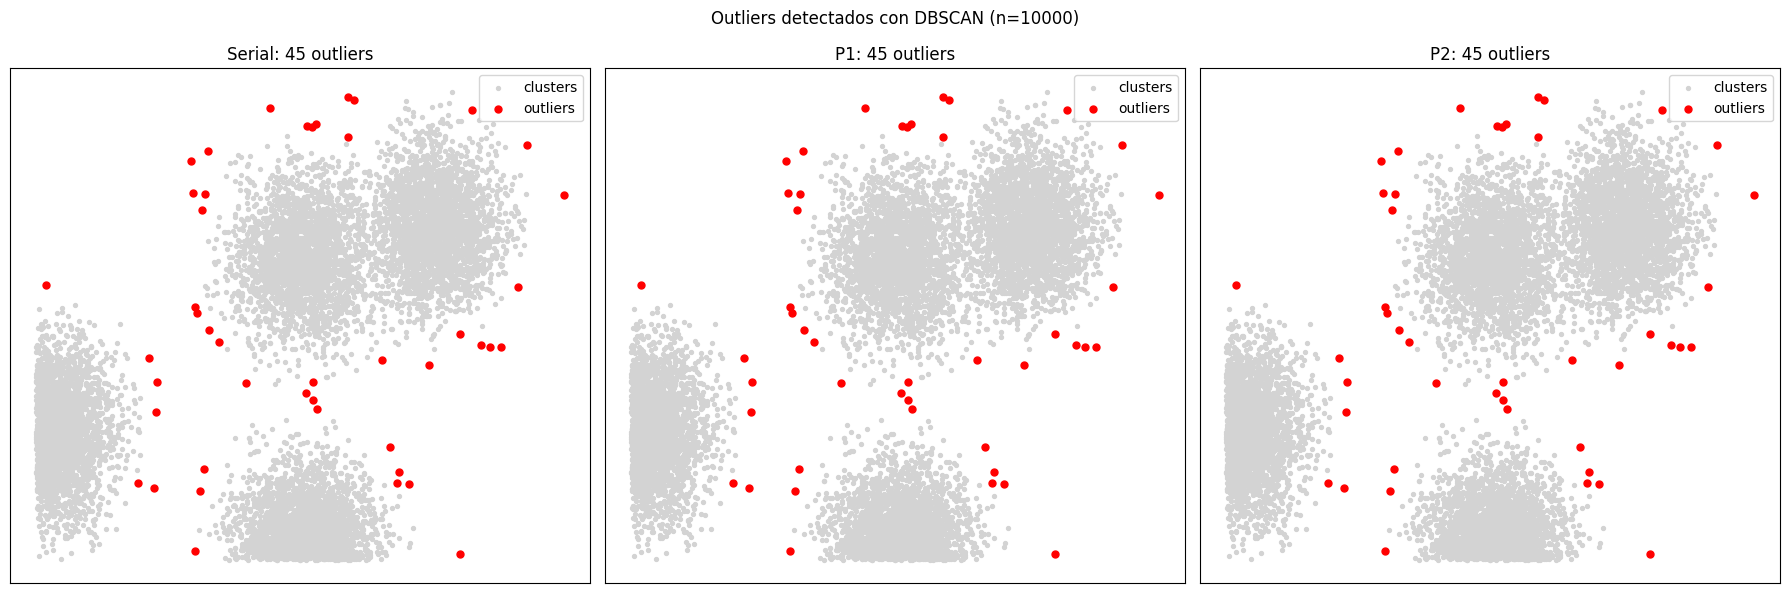

Las 3 versiones coinciden: True


In [2]:
results = {name: np.loadtxt(cmd[2], delimiter=",") for name, cmd in runs.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    noise = r[:, 2] == 0
    ax.scatter(r[~noise, 0], r[~noise, 1], c="lightgray", s=8, label="clusters")
    ax.scatter(r[noise, 0], r[noise, 1], c="red", s=25, label="outliers")
    ax.set_title(f"{name}: {noise.sum()} outliers")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="upper right")
plt.suptitle(f"Outliers detectados con DBSCAN (n={N})")
plt.tight_layout()
plt.show()

masks = [r[:, 2] == 0 for r in results.values()]
print("Las 3 versiones coinciden:", all((masks[0] == m).all() for m in masks[1:]))